# 05 · Hidden Markov Models: Forward and Viterbi

**Covers:** Lab Exercise 5 (professor's tests) and Assignment 5 (Forward proof, Viterbi by hand).

### Theory in one cell
An HMM is defined by three objects:
- $\pi_i = P(X_1 = i)$ – initial distribution
- $a_{ij} = P(X_{t+1}=j \mid X_t = i)$ – transition matrix **A** (row = from, column = to)
- $b_j(o) = P(O_t = o \mid X_t = j)$ – emission matrix **B** (row = state, column = symbol)

Joint probability of a path and the observations:
$$P(x_{1:T}, o_{1:T}) = \pi_{x_1} b_{x_1}(o_1)\prod_{t=2}^T a_{x_{t-1}x_t}\,b_{x_t}(o_t)$$

| Question | Algorithm | Recursion |
|---|---|---|
| $P(o_{1:T})$ | **Forward** | $\alpha_1(j) = \pi_j b_j(o_1)$, $\alpha_t(j) = b_j(o_t)\sum_i \alpha_{t-1}(i)a_{ij}$, $P(o) = \sum_j\alpha_T(j)$ |
| $\arg\max_x P(x,o)$ | **Viterbi** | $\delta_1(j) = \pi_j b_j(o_1)$, $\delta_t(j) = b_j(o_t)\max_i \delta_{t-1}(i)a_{ij}$, $\psi_t(j) = \arg\max_i(\cdot)$ |
| $P(X_t\mid o)$ | Forward–Backward | $\alpha_t(j)\beta_t(j)/P(o)$ |

Brute force costs $O(N^T)$; Forward and Viterbi cost $O(T\,N^2)$.

## Exercise 1 · Proof of the Forward algorithm (Assignment 5)

Define $\alpha_t(j) = P(O_1=o_1,\dots,O_t=o_t,\ X_t=j)$.

**a) Initialisation.** $\alpha_1(j) = P(O_1=o_1, X_1=j) = P(X_1=j)\,P(O_1=o_1\mid X_1=j) = \pi_j\,b_j(o_1)$ (product rule).

**b) Recursion.** Condition on the previous state (law of total probability):
$$\alpha_t(j) = \sum_i P(o_{1:t-1}, X_{t-1}=i, X_t=j, o_t)
= \sum_i \underbrace{P(o_{1:t-1}, X_{t-1}=i)}_{\alpha_{t-1}(i)}\ \underbrace{P(X_t=j\mid X_{t-1}=i)}_{a_{ij}}\ \underbrace{P(o_t\mid X_t=j)}_{b_j(o_t)}$$
using the Markov property ($X_t$ depends only on $X_{t-1}$) and that $o_t$ depends only on $X_t$.
Taking $b_j(o_t)$ out of the sum gives $\alpha_t(j) = b_j(o_t)\sum_i\alpha_{t-1}(i)a_{ij}$.

**c) Termination.** Marginalise the last state: $P(o_{1:T}) = \sum_j P(o_{1:T}, X_T=j) = \sum_j \alpha_T(j)$. ∎

In [1]:
%pip install -q hmmlearn networkx matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from pathlib import Path
from hmmlearn import hmm                 # CategoricalHMM = HMM with discrete observations

FIG = Path("figures")
FIG.mkdir(exist_ok=True)

## Exercise 2 · The professor's tests (Lab 5 + Assignment 5)

Hidden state = difficulty of the test: **D** (difficult), **M** (medium), **E** (easy).
Observation = the student's grade: **VG**, **G**, **S**, **U**.

- First test: the three difficulties are equally likely → $\pi = (1/3, 1/3, 1/3)$.
- After a difficult test the next one is M or E with prob. 0.5 each.
- After M or E the next is D with 0.5, M with 0.25, E with 0.25.

**a) Model**

In [3]:
states = ["D", "M", "E"]                 # hidden states
grades = ["VG", "G", "S", "U"]           # observation symbols

pi = np.full(3, 1 / 3)                   # initial distribution
A = np.array([[0.0, 0.5,  0.5 ],         # from D
              [0.5, 0.25, 0.25],         # from M
              [0.5, 0.25, 0.25]])        # from E
B = np.array([[0.10, 0.20, 0.40, 0.30],  # D emits VG, G, S, U
              [0.15, 0.25, 0.50, 0.10],  # M
              [0.20, 0.30, 0.40, 0.10]]) # E

# Every row of A and B must sum to 1
print("rows of A:", A.sum(axis=1), "  rows of B:", B.sum(axis=1))

# The observed sequence, converted to integer indices 0..3
obs_names = ["VG", "VG", "S", "G", "G", "S", "G", "G", "U", "G", "G", "S"]
o = np.array([grades.index(g) for g in obs_names])
print("observations as indices:", o)

rows of A: [1. 1. 1.]   rows of B: [1. 1. 1.]
observations as indices: [0 0 2 1 1 2 1 1 3 1 1 2]


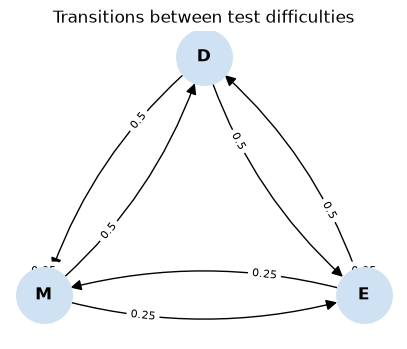

In [4]:
# State-transition diagram (only the transitions with probability > 0)
G = nx.DiGraph()
for i in range(3):
    for j in range(3):
        if A[i, j] > 0:
            G.add_edge(states[i], states[j], p=A[i, j])
pos = {"D": (0, 1), "M": (-1, -0.5), "E": (1, -0.5)}
plt.figure(figsize=(5, 4))
nx.draw_networkx(G, pos, node_size=1600, node_color="#cfe2f3", arrowsize=16,
                 connectionstyle="arc3,rad=0.15", font_weight="bold")
nx.draw_networkx_edge_labels(G, pos, {(u, v): d["p"] for u, v, d in G.edges(data=True)},
                             connectionstyle="arc3,rad=0.15", label_pos=0.3, font_size=8)
plt.axis("off")
plt.title("Transitions between test difficulties")
plt.savefig(FIG / "05_transition_diagram.png", dpi=150, bbox_inches="tight")
plt.show()

### b–e) Viterbi implemented by hand
Two tables: `delta[t, j]` = best score of a path ending in state j at time t, and
`psi[t, j]` = **which previous state** that best path came from. `psi` is what lets us
rebuild the path backwards at the end (backtracking).

In [5]:
def viterbi(pi, A, B, o):
    T, N = len(o), len(pi)
    delta = np.zeros((T, N))                  # scores
    psi = np.zeros((T, N), dtype=int)         # back-pointers

    delta[0] = pi * B[:, o[0]]                # initialisation: delta_1(j) = pi_j b_j(o_1)
    for t in range(1, T):
        # cand[i, j] = delta_{t-1}(i) * a_ij  (score of arriving to j from i)
        cand = delta[t - 1][:, None] * A
        psi[t] = cand.argmax(axis=0)          # best previous state for each j
        delta[t] = B[:, o[t]] * cand.max(axis=0)

    # termination: best final state, then follow psi backwards
    path = [int(delta[-1].argmax())]
    for t in range(T - 1, 0, -1):
        path.insert(0, int(psi[t, path[0]]))
    return path, delta[-1].max(), delta, psi


path, p_best, delta, psi = viterbi(pi, A, B, o)

# d) intermediate check
print("delta_1 =", np.round(delta[0], 5))
print("delta_2 =", np.round(delta[1], 5))
# by hand: delta_2(D) = b_D(VG) * max(delta_1(D)*0, delta_1(M)*0.5, delta_1(E)*0.5) = 0.1 * 0.0667*0.5
print("check delta_2(D) by hand:", 0.1 * max(delta[0, 0] * 0, delta[0, 1] * 0.5, delta[0, 2] * 0.5))

# e) the most probable sequence and its JOINT probability
print("\nViterbi path:", [states[s] for s in path])
print(f"max P(x_1..x_12, o_1..o_12) = {p_best:.4e}")

delta_1 = [0.03333 0.05    0.06667]
delta_2 = [0.00333 0.0025  0.00333]
check delta_2(D) by hand: 0.0033333333333333335

Viterbi path: ['D', 'E', 'D', 'E', 'D', 'M', 'D', 'E', 'D', 'E', 'D', 'M']
max P(x_1..x_12, o_1..o_12) = 2.1094e-11


In [6]:
# Forward by hand: P(o) and then P(best path | o) = P(path, o) / P(o)
def forward(pi, A, B, o):
    alpha = np.zeros((len(o), len(pi)))
    alpha[0] = pi * B[:, o[0]]                          # initialisation
    for t in range(1, len(o)):
        alpha[t] = B[:, o[t]] * (alpha[t - 1] @ A)      # recursion (vector form)
    return alpha

alpha = forward(pi, A, B, o)
p_obs = alpha[-1].sum()                                 # termination
print(f"P(o) = {p_obs:.4e}")
print(f"P(best path | o) = {p_best / p_obs:.4f}")

P(o) = 7.3259e-08
P(best path | o) = 0.0003


### Same model with hmmlearn

In [7]:
model = hmm.CategoricalHMM(n_components=3, init_params="", params="")   # "" = do not re-initialise / fit
model.n_features = 4                       # number of observation symbols
model.startprob_ = pi
model.transmat_ = A
model.emissionprob_ = B

X = o.reshape(-1, 1)                       # hmmlearn wants a COLUMN of integers, shape (T, 1)
log_p, lib_path = model.decode(X, algorithm="viterbi")
print("hmmlearn Viterbi:", [states[s] for s in lib_path], f" P = {np.exp(log_p):.4e}")
print(f"hmmlearn P(o) (score is a log-probability) = {np.exp(model.score(X)):.4e}")

# Most probable state at each t SEPARATELY (posterior / smoothing)
posterior = model.predict_proba(X)
print("Per-time maxima:", [states[s] for s in posterior.argmax(axis=1)])

hmmlearn Viterbi: ['E', 'E', 'D', 'E', 'D', 'M', 'D', 'E', 'D', 'E', 'D', 'M']  P = 2.1094e-11
hmmlearn P(o) (score is a log-probability) = 7.3259e-08
Per-time maxima: ['E', 'E', 'D', 'E', 'E', 'M', 'D', 'E', 'D', 'E', 'D', 'M']


**Note – a tie.** The paths starting with D,E,… and E,E,… have the same probability
($\tfrac13\cdot0.1\cdot0.5 = \tfrac13\cdot0.2\cdot0.25$). My `argmax` returns the first index (D) and
hmmlearn returns E. Both answers are correct and have the same probability.

**f) Interpretation.** Viterbi finds the most probable **complete sequence** of difficulties.
Picking the most probable state at each time separately (last line above) can give a different
sequence – even an impossible one (e.g. D → D has probability 0 here). The value from e) is the
**joint** probability $P(x^*, o)$, not $P(x^*\mid o)$; for the latter divide by $P(o)$ from Forward.